# Onset coupling: why the first year of a trend window predicts the trend

A common way to label decadal slowdowns is to fit a linear trend over the ten years that start at an onset year $t$ and then ask whether a predictor observed at $t$ can tell which decades will be slow. This notebook shows that such a label is correlated with the state at $t$ by construction. The onset value is one of the ten numbers the trend is computed from, so it "predicts" the trend even when every year is independent random noise and nothing about the future can be known.

The effect is a form of what biostatisticians call mathematical coupling, first written down for the relation between an initial value and a subsequent change {cite:p}`Oldham62` and reviewed many times since {cite:p}`Archie81,Tu07,Barnett05`. The geosciences know it as spurious self-correlation {cite:p}`Pearson1897,Kenney82`, and machine learning knows the broader family as leakage {cite:p}`Kaufman12,Kapoor23`. Here we derive the trend-window version step by step, verify each step numerically, and show how starting the window one year later removes it.

The derivation follows the standard least-squares results in {cite:t}`Wilks19` and {cite:t}`Hyndman21`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

ORANGE, BLUE, INK, GREY = "#D55E00", "#0072B2", "#1f2933", "#8a949e"
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(2026)


def ols_slope(y, axis=-1):
    "Least-squares slope of y against 0, 1, ..., n-1 along `axis`."
    y = np.moveaxis(np.asarray(y, float), axis, -1)
    i = np.arange(y.shape[-1])
    return ((i - i.mean()) * y).sum(-1) / ((i - i.mean()) ** 2).sum()

## 1. The least-squares trend is a weighted sum of the values

This step holds for any window length and any data.

Let $y_0, y_1, \ldots, y_{n-1}$ be $n$ annual values, indexed by the year in the window $i = 0, \ldots, n-1$. We fit the line

$$ y_i \approx a + b\,i , $$

where $a$ is the intercept and $b$ is the trend per year. Least squares chooses $a$ and $b$ to minimise

$$ E(a,b) = \sum_{i=0}^{n-1} \left(y_i - a - b\,i\right)^2 . $$

Setting $\partial E/\partial a = 0$ gives $a = \bar y - b\,\bar i$, so the fitted line passes through the centre of the data $(\bar i, \bar y)$. Setting $\partial E/\partial b = 0$ and substituting $a$ gives the familiar slope

$$ b = \frac{\sum_{i}(i-\bar i)(y_i-\bar y)}{\sum_{i}(i-\bar i)^2} , $$

which is the covariance of year and value divided by the variance of year.

The $\bar y$ term can be dropped from the numerator. Expanding,

$$ \sum_{i}(i-\bar i)(y_i-\bar y) = \sum_{i}(i-\bar i)\,y_i \;-\; \bar y \sum_{i}(i-\bar i) , $$

and the distances from the mean year sum to zero, $\sum_i (i-\bar i) = 0$. Therefore

$$ \boxed{\, b = \sum_{i=0}^{n-1} w_i\, y_i , \qquad w_i = \frac{i-\bar i}{\sum_{j}(j-\bar j)^2} \,} $$

Every year enters the trend with a fixed weight. Years before the middle of the window count negatively, years after it count positively, and the first year gets the most negative weight because it is farthest from the middle.

In [2]:
# check: the weighted sum equals numpy's least-squares fit for arbitrary data
y = rng.standard_normal(10)
i = np.arange(10)
print("weighted sum :", ols_slope(y))
print("np.polyfit   :", np.polyfit(i, y, 1)[0])

weighted sum : 0.03936124043393376
np.polyfit   : 0.03936124043393376


## 2. The weights for a ten-year window

From here on we use $n = 10$, the window length of the slowdown labels. The mean year index is

$$ \bar i = \frac{0+1+\cdots+9}{10} = \frac{45}{10} = 4.5 . $$

The denominator is the sum of squared distances from 4.5,

$$
\begin{aligned}
D &= \sum_{i=0}^{9}(i-4.5)^2 \\
  &= 2\left(4.5^2 + 3.5^2 + 2.5^2 + 1.5^2 + 0.5^2\right) \\
  &= 2\,(20.25 + 12.25 + 6.25 + 2.25 + 0.25) \\
  &= 82.5 .
\end{aligned}
$$

Substituting,

$$ b = \frac{-4.5\,y_0 - 3.5\,y_1 - 2.5\,y_2 - 1.5\,y_3 - 0.5\,y_4 + 0.5\,y_5 + 1.5\,y_6 + 2.5\,y_7 + 3.5\,y_8 + 4.5\,y_9}{82.5} , $$

so that

$$ w_i = \frac{i-4.5}{82.5}, \qquad w_0 = \frac{-4.5}{82.5} = -0.0545\ldots $$

The starting value enters the trend directly and with a negative sign. Holding the other nine values fixed, raising $y_0$ by one unit lowers the fitted trend by 0.0545 units per year.

mean year = 4.5,  D = 82.5,  w0 = -0.0545


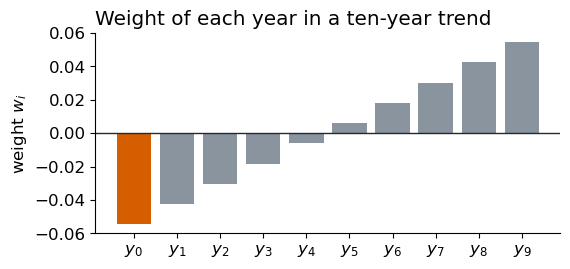

In [3]:
n = 10
i = np.arange(n)
D = ((i - i.mean()) ** 2).sum()
w = (i - i.mean()) / D
print(f"mean year = {i.mean()},  D = {D},  w0 = {w[0]:.4f}")

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.bar(i, w, color=[ORANGE] + [GREY] * (n - 1))
ax.axhline(0, color=INK, lw=1)
ax.set_xticks(i, [f"$y_{k}$" for k in i])
ax.set_ylabel("weight $w_i$")
ax.set_title("Weight of each year in a ten-year trend", loc="left")
plt.show()

## 3. A white-noise example

To see the effect without any physics, take a series in which every year is an independent draw from a distribution with mean zero and variance one,

$$ \operatorname{Var}(y_i) = 1, \qquad \operatorname{Cov}(y_i, y_j) = 0 \quad (i \ne j) . $$

Nothing about the future can be predicted from such a series. Below is one realisation, chosen so that the value at $t$ is high. Two trends are fitted. The orange one uses the ten years $t \ldots t+9$, so it contains $y_t$. The blue one uses $t+1 \ldots t+10$, so it does not.

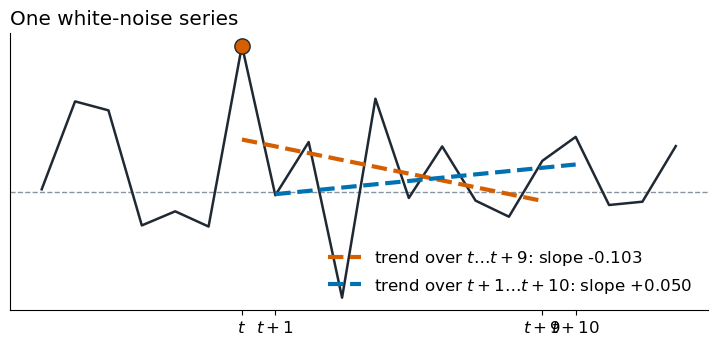

In [4]:
r = np.random.default_rng(11)
y = np.clip(r.standard_normal(20), -1.6, 1.4)
t = 6
y[t] = 2.2                      # a high onset value, to make the effect visible
yrs = np.arange(y.size)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axhline(0, color=GREY, lw=1, ls="--")
ax.plot(yrs, y, color=INK, lw=1.8)
for start, col, lab in ((t, ORANGE, "trend over $t \\ldots t+9$"), (t + 1, BLUE, "trend over $t+1 \\ldots t+10$")):
    xs = np.arange(start, start + n)
    p = np.polyfit(xs, y[xs], 1)
    ax.plot(xs, np.polyval(p, xs), color=col, lw=3, ls="--", label=f"{lab}: slope {p[0]:+.3f}")
ax.plot(t, y[t], "o", ms=11, mfc=ORANGE, mec=INK, zorder=5)
ax.set_xticks([t, t + 1, t + 9, t + 10], ["$t$", "$t+1$", "$t+9$", "$t+10$"])
ax.set_yticks([])
ax.legend(frameon=False, loc="lower right")
ax.set_title("One white-noise series", loc="left")
plt.show()

The high value at $t$ tilts the first trend down. The second trend never sees it. One series proves nothing, so the next steps compute what happens on average over many series.

## 4. What "correlation" means here

Imagine generating many ten-year sequences. For each one we record its starting value $y_0$ and its fitted trend $b$. We want the correlation between those two numbers across sequences, $\operatorname{Corr}(y_0, b)$.

### Covariance between the starting value and the trend

Because $b$ is a weighted sum,

$$
\begin{aligned}
\operatorname{Cov}(y_0, b) &= \operatorname{Cov}\left(y_0,\; w_0 y_0 + w_1 y_1 + \cdots + w_9 y_9\right) \\
&= w_0 \operatorname{Cov}(y_0,y_0) + w_1 \operatorname{Cov}(y_0,y_1) + \cdots + w_9 \operatorname{Cov}(y_0,y_9) .
\end{aligned}
$$

Independence makes every term involving a different year zero, and $\operatorname{Cov}(y_0,y_0) = \operatorname{Var}(y_0) = 1$, so

$$ \boxed{\operatorname{Cov}(y_0, b) = w_0 = -\frac{4.5}{82.5}} $$

This is the shared information. The same $y_0$ appears in both quantities.

### Variance of the trend

For a weighted sum,

$$ \operatorname{Var}(b) = \sum_{i} w_i^2 \operatorname{Var}(y_i) + 2\sum_{i<j} w_i w_j \operatorname{Cov}(y_i, y_j) . $$

Independence removes the cross terms and each variance is one, so

$$
\operatorname{Var}(b) = \sum_{i=0}^{9} \left(\frac{i-4.5}{82.5}\right)^2 = \frac{82.5}{82.5^2} = \frac{1}{82.5},
\qquad
\boxed{\operatorname{SD}(b) = \sqrt{1/82.5} \approx 0.110}
$$

### Correlation

$$
r = \frac{\operatorname{Cov}(y_0,b)}{\operatorname{SD}(y_0)\,\operatorname{SD}(b)}
  = \frac{-4.5/82.5}{1 \times \sqrt{1/82.5}}
  = -\frac{4.5}{\sqrt{82.5}} \approx \boxed{-0.495},
\qquad
r^2 = \frac{4.5^2}{82.5} = \frac{20.25}{82.5} \approx \boxed{0.245}
$$

About a quarter of the variance of the trend is explained by the starting value alone, in a series where nothing is predictable. No normality assumption is needed, only independence and equal variance.

In [5]:
N = 200_000
Y = rng.standard_normal((N, n + 1))          # n+1 years so both windows fit
B_t, B_t1 = ols_slope(Y[:, :n]), ols_slope(Y[:, 1:])
y_t = Y[:, 0]

print(f"Cov(y_t, B_t)  simulated {np.cov(y_t, B_t)[0, 1]:+.4f}   theory {w[0]:+.4f}")
print(f"SD(B_t)        simulated {B_t.std():.4f}    theory {np.sqrt(1 / D):.4f}")
r_t = np.corrcoef(y_t, B_t)[0, 1]
print(f"Corr(y_t, B_t) simulated {r_t:+.4f}   theory {-4.5 / np.sqrt(D):+.4f}   (r^2 = {r_t**2:.3f})")

Cov(y_t, B_t)  simulated -0.0546   theory -0.0545
SD(B_t)        simulated 0.1101    theory 0.1101
Corr(y_t, B_t) simulated -0.4945   theory -0.4954   (r^2 = 0.245)


## 5. Why this looks like forecasting skill

Split the trend into the part fixed by the starting value and the part made of future values,

$$ b = \underbrace{w_0 y_0}_{\text{known at the start}} \; + \; \underbrace{\sum_{i=1}^{9} w_i y_i}_{\text{unknown future}} . $$

Under white noise the future values still have mean zero after $y_0$ is observed, so

$$ \mathbb{E}[\,b \mid y_0\,] = w_0 y_0 + \sum_{i=1}^{9} w_i\, \mathbb{E}[\,y_i \mid y_0\,] = w_0 y_0 = -0.0545\, y_0 . $$

A model can therefore estimate the trend from $y_0$ alone, with no information about any future year. A high start makes a negative trend more likely because the later values are centred on the mean, and a low start makes a positive trend more likely. In a large ensemble this looks exactly like skill at predicting slow and fast decades.

The negative correlation is between the starting value and the trend. A forecast that uses the negative coefficient correctly is positively correlated with the realised trend.

## 6. Starting the window one year later

With the same weights the two possible targets are

$$ B_t = w_0 y_t + w_1 y_{t+1} + \cdots + w_9 y_{t+9} $$

and

$$ B_{t+1} = w_0 y_{t+1} + w_1 y_{t+2} + \cdots + w_9 y_{t+10} . $$

For the first target $y_t$ appears directly,

$$ \operatorname{Cov}(y_t, B_t) = w_0 \operatorname{Var}(y_t) + \sum_{i=1}^{9} w_i \operatorname{Cov}(y_t, y_{t+i}) = w_0 \times 1 + 0 = -0.0545 . $$

For the second target every term involves a future value that is independent of $y_t$,

$$ \operatorname{Cov}(y_t, B_{t+1}) = \sum_{i=0}^{9} w_i \operatorname{Cov}(y_t, y_{t+1+i}) = 0 . $$

The best predictions under this white-noise model are therefore

$$ \boxed{\mathbb{E}[\,B_t \mid y_t\,] = -0.0545\, y_t} \qquad \text{versus} \qquad \boxed{\mathbb{E}[\,B_{t+1} \mid y_t\,] = 0} $$

Each dot below is one simulated series.

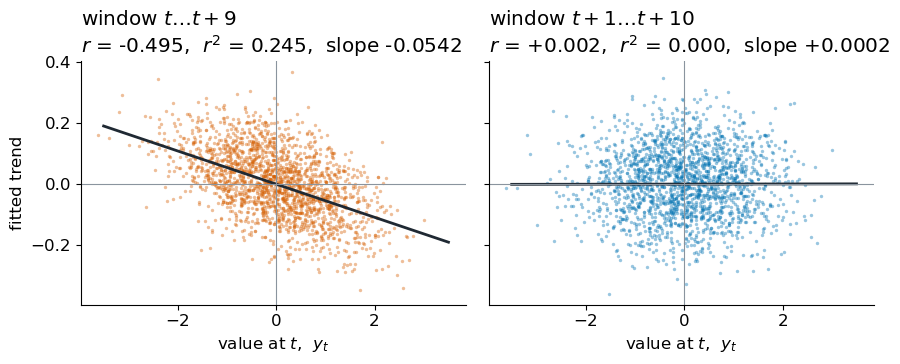

In [6]:
k = rng.choice(N, 2000, replace=False)
fig, axs = plt.subplots(1, 2, figsize=(9, 3.8), sharex=True, sharey=True)
for ax, B, col, title in ((axs[0], B_t, ORANGE, "window $t \\ldots t+9$"),
                          (axs[1], B_t1, BLUE, "window $t+1 \\ldots t+10$")):
    r = np.corrcoef(y_t, B)[0, 1]
    ax.scatter(y_t[k], B[k], s=6, color=col, alpha=0.4, lw=0)
    p = np.polyfit(y_t, B, 1)
    ax.plot([-3.5, 3.5], np.polyval(p, [-3.5, 3.5]), color=INK, lw=2)
    ax.axhline(0, color=GREY, lw=0.8); ax.axvline(0, color=GREY, lw=0.8)
    ax.set_title(f"{title}\n$r$ = {r:+.3f},  $r^2$ = {r**2:.3f},  slope {p[0]:+.4f}", loc="left")
    ax.set_xlabel("value at $t$,  $y_t$")
axs[0].set_ylabel("fitted trend")
plt.tight_layout(); plt.show()

## 7. Any window length

The same steps give, for a window of $n$ years that contains the onset,

$$ r = \frac{-\bar i}{\sqrt{\sum_i (i-\bar i)^2}} = -\sqrt{\frac{3(n-1)}{n(n+1)}}, \qquad r^2 = \frac{3(n-1)}{n(n+1)} . $$

For $n = 2$ the trend is just the change $y_1 - y_0$ and $r = -1/\sqrt 2 \approx -0.71$, which is Oldham's original result for change against initial value {cite:p}`Oldham62`. Longer windows dilute the onset value but never remove it. The simple average of the yearly changes would be worse, because it telescopes to $(y_{n-1} - y_0)/(n-1)$ and keeps $r^2 = 0.5$ for every $n$.

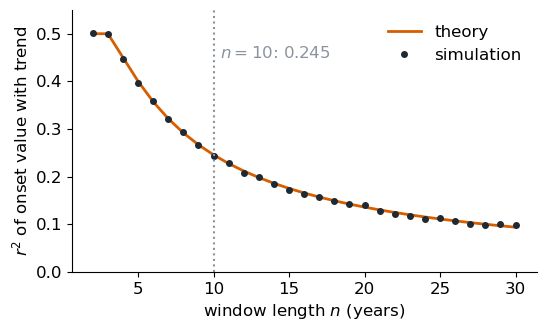

In [7]:
ns = np.arange(2, 31)
r2_theory = 3 * (ns - 1) / (ns * (ns + 1))
r2_sim = [np.corrcoef(Y2[:, 0], ols_slope(Y2))[0, 1] ** 2
          for Y2 in (rng.standard_normal((50_000, m)) for m in ns)]

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(ns, r2_theory, color=ORANGE, lw=2, label="theory")
ax.plot(ns, r2_sim, "o", ms=4, color=INK, label="simulation")
ax.axvline(10, color=GREY, ls=":"); ax.text(10.4, 0.45, "$n=10$: 0.245", color=GREY)
ax.set_xlabel("window length $n$ (years)"); ax.set_ylabel("$r^2$ of onset value with trend")
ax.set_ylim(0, 0.55); ax.legend(frameon=False)
plt.show()

## 8. When the series has memory

Real sea ice is not white noise. Its anomalies persist from one year to the next, so the state at $t$ carries genuine information about the following years. A first-order autoregressive series, $y_{t+1} = \phi\, y_t + \varepsilon$, separates the two effects. With the window starting at $t$, the onset value explains the arithmetic part plus the persistence. With the window starting at $t+1$ or $t+2$, only the persistence is left.

In [8]:
def ar1(phi, N, L):
    "N independent AR(1) series of length L with unit variance."
    y = np.empty((N, L)); y[:, 0] = rng.standard_normal(N)
    for j in range(1, L):
        y[:, j] = phi * y[:, j - 1] + np.sqrt(1 - phi**2) * rng.standard_normal(N)
    return y

print("phi    start t   start t+1   start t+2")
for phi in (0.0, 0.3, 0.6):
    Yp = ar1(phi, 100_000, n + 2)
    r2 = [np.corrcoef(Yp[:, 0], ols_slope(Yp[:, s:s + n]))[0, 1] ** 2 for s in (0, 1, 2)]
    print(f"{phi:.1f}   " + "   ".join(f"{v:9.3f}" for v in r2))

phi    start t   start t+1   start t+2
0.0       0.246       0.000       0.000
0.3       0.276       0.026       0.003
0.6       0.337       0.119       0.041


In CESM2-LE the September sea-ice extent anomaly at onset explains $r^2 = 0.28$ of the following ten-year trend anomaly when the window starts at $t$, 0.075 when it starts at $t+1$ and 0.04 when it starts at $t+2$. Pure noise would give 0.245 in the first case, so most of the onset-inclusive skill is arithmetic, and the 0.075 that survives the offset is the real persistence of the ice. Global-mean temperature, the target of {cite:t}`Labe22`, behaves the same way: 0.26, 0.03 and 0.00.

## 9. When the problem appears

Two conditions are needed at once.

1. The target contains a value that is already known, or nearly known, when the forecast is made. A trend whose window starts at $t$ qualifies, as does a change $y_{t+k} - y_t$ or an anomaly relative to the starting value.
2. The predictor carries information about that value. It can be the value itself, a contemporaneous field, a proxy such as summer Arctic SST for September ice extent or upper-ocean heat content for global temperature, or a field that leads it by only a few months.

The usual temporal leakage check does not catch this. No target year lies before the predictor, because the leak runs through the algebra of the label rather than through time. A proxy passes on a fraction of the coupling. If the predictor $x$ has correlation $\rho$ with $y_t$ and no other information, its $r^2$ with the onset-inclusive trend is about $\rho^2 \times 0.245$.

In [9]:
for rho in (0.5, 0.8, 0.95):
    x = rho * y_t + np.sqrt(1 - rho**2) * rng.standard_normal(N)    # a noisy proxy of y_t
    print(f"proxy with rho = {rho:.2f}:  r^2 with B_t = {np.corrcoef(x, B_t)[0, 1]**2:.3f}"
          f"   (rho^2 x 0.245 = {rho**2 * 0.245:.3f}),  with B_t+1 = {np.corrcoef(x, B_t1)[0, 1]**2:.3f}")

proxy with rho = 0.50:  r^2 with B_t = 0.061   (rho^2 x 0.245 = 0.061),  with B_t+1 = 0.000
proxy with rho = 0.80:  r^2 with B_t = 0.158   (rho^2 x 0.245 = 0.157),  with B_t+1 = 0.000
proxy with rho = 0.95:  r^2 with B_t = 0.220   (rho^2 x 0.245 = 0.221),  with B_t+1 = 0.000


### A short checklist for trend-type targets

* Write the target as a weighted sum of yearly values and check whether any of those years is the forecast year or within a few months of it.
* Regress the target on its own state at onset and compare with the white-noise value $3(n-1)/[n(n+1)]$.
* Repeat with the window starting at $t+1$ and $t+2$. What survives is predictability; what disappears was arithmetic.
* Compare any model, and any explanation of it, with a regression on the onset state before reading physics into it {cite:p}`Hoffman25`.

## References

```{bibliography}
```